In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
from scipy.stats import pearsonr

warnings.filterwarnings('ignore')

In [4]:
# Creating database connection
conn = sqlite3.connect('vendorinventory.db')

# Fetching vendor summary data
df = pd.read_sql_query("SELECT * FROM vendor_sales_summary", conn)

df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897


## Exploratory Data Analysis

\- Previously, we examined the various tables in the database to identify key variables, understand their relationships, and determine which ones should be included in the final analysis.

\- In this phase of EDA, we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identify anomalies, and ensure data quality before proceeding with further analysis.

In [5]:
# summary statistics
df.describe()

,VendorNumber,Brand,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
count,10692.000000,10692.000000,10692.000000,10692.000000,10692.000000,10692.000000,1.069200e+04,10692.000000,1.069200e+04,10692.000000,10692.000000,10692.000000,1.069200e+04,1.069200e+04,10692.000000,10692.000000
mean,10650.649458,18039.228769,24.385303,35.643671,847.360550,3140.886831,3.010669e+04,3077.482136,4.223907e+04,18793.783627,1774.226259,61433.763214,1.213238e+04,-inf,1.706793,2.504390
std,18753.519148,12662.187074,109.269375,148.246016,664.309212,11095.086769,1.230678e+05,10952.851391,1.676553e+05,44952.773386,10975.582240,60938.458032,4.622434e+04,NaN,6.020460,8.459067
min,2.000000,58.000000,0.360000,0.490000,50.000000,1.000000,7.100000e-01,0.000000,0.000000e+00,0.000000,0.000000,0.090000,-5.200278e+04,-inf,0.000000,0.000000
25%,3951.000000,5793.500000,6.840000,10.990000,750.000000,36.000000,4.534575e+02,33.000000,7.292200e+02,289.710000,4.800000,14069.870000,5.292000e+01,1.332451e+01,0.807229,1.153729
50%,7153.000000,18761.500000,10.455000,15.990000,750.000000,262.000000,3.655465e+03,261.000000,5.298045e+03,2857.800000,46.570000,50293.620000,1.399640e+03,3.040546e+01,0.981529,1.436894
75%,9552.000000,25514.250000,19.482500,28.990000,750.000000,1975.750000,2.073825e+04,1929.250000,2.839692e+04,16059.562500,418.650000,79528.990000,8.660200e+03,3.995613e+01,1.039342,1.665449
max,201359.000000,90631.000000,5681.810000,7499.990000,20000.000000,337660.000000,3.811252e+06,334939.000000,5.101920e+06,672819.310000,368242.800000,257032.070000,1.290668e+06,9.971666e+01,274.500000,352.928571


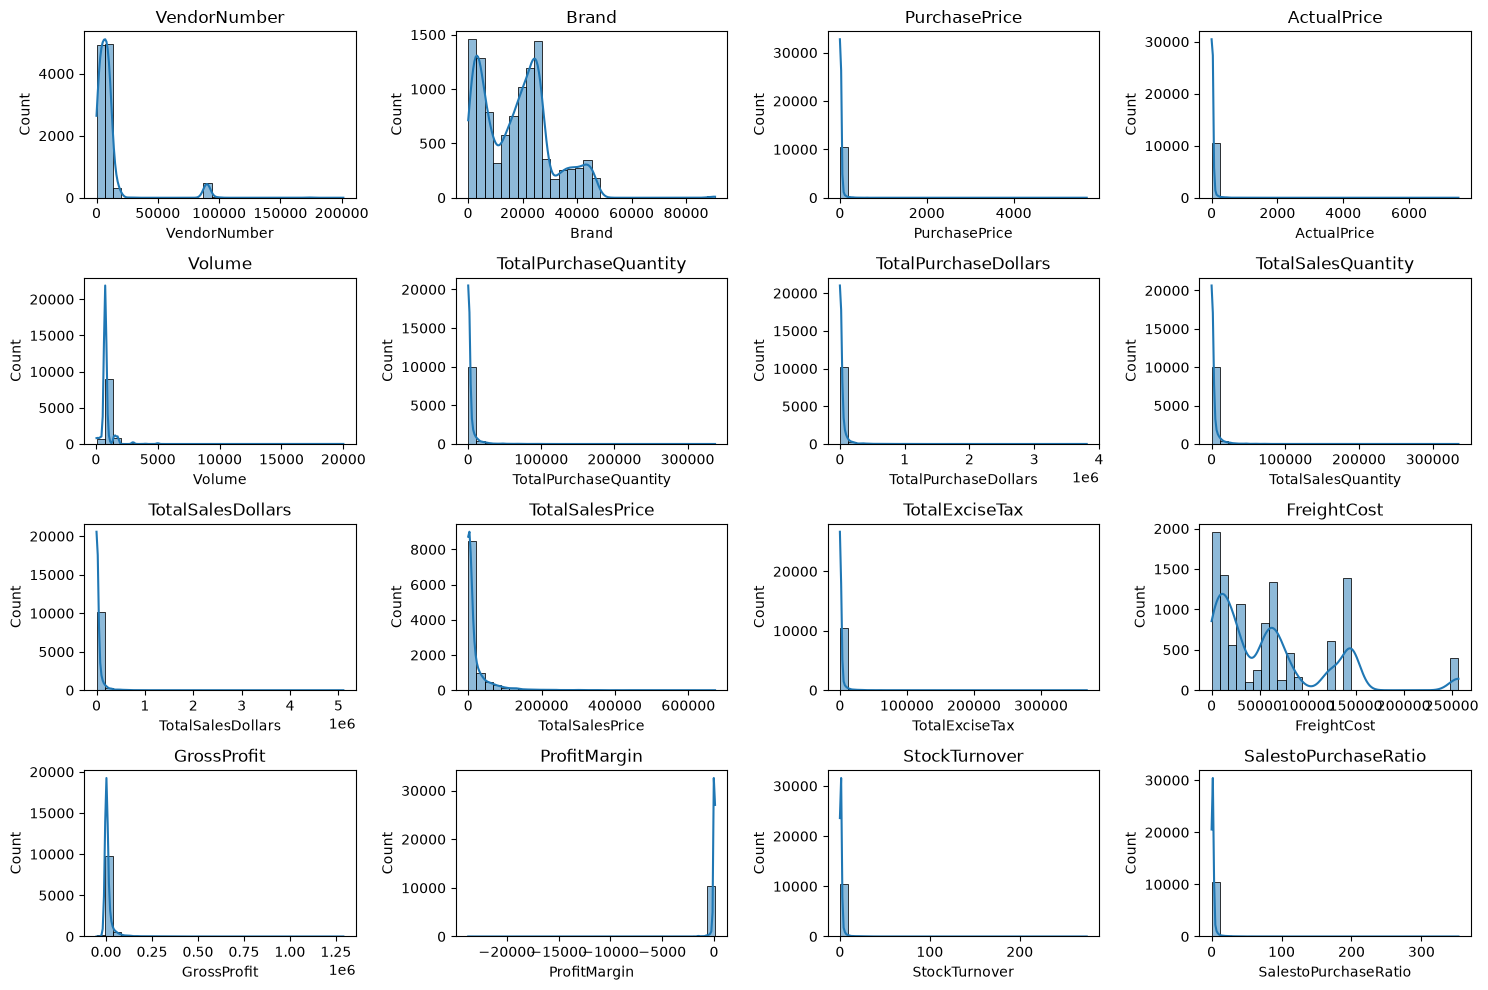

In [6]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

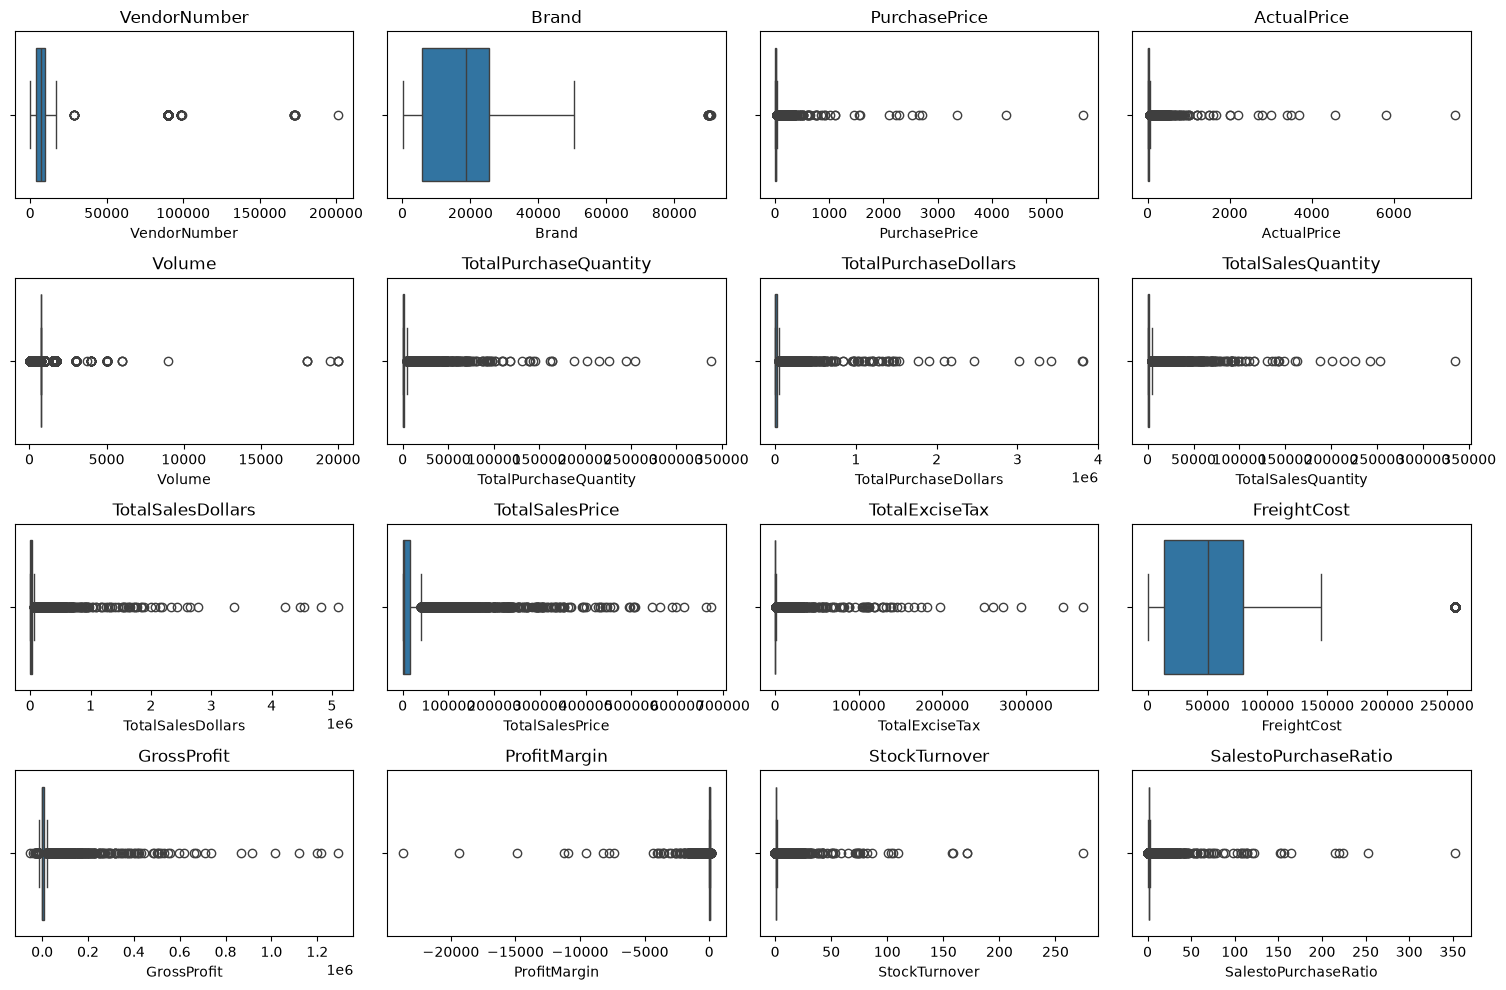

In [7]:
# Outlier Detection with Boxplots
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

## Summary Statistics Insights

**Negative & Zero Values:**

- **Gross Profit:** Minimum value is **−52,002.78**, indicating losses. Some products or transactions may be selling at a loss due to high costs or selling at discounts lower than the purchase price.
- **Profit Margin:** Has a minimum of **−∞**, which suggests cases where revenue is zero or the calculation is invalid. In this project, division by zero can cause this value.
- **Total Sales Quantity & Sales Dollars:** Minimum values are **0**, meaning some products were purchased but never sold. These could represent slow-moving or obsolete stock.

**Outliers Indicated by High Standard Deviations:**

- **Purchase & Actual Prices:** The maximum values (**5,681.81** and **7,499.99**) are significantly higher than the means (**24.39** and **35.64**), indicating potential premium products or unusual values that need investigation.
- **Freight Cost:** Huge variation, from **0.09** to **257,032.07**, suggests differences in logistics costs or bulk shipments.
- **Stock Turnover:** Ranges from **0** to **274.5**, implying some products sold extremely fast while others remained in stock. Values greater than 1 indicate that sales quantity exceeded purchase quantity in the summarized data, potentially because sales were fulfilled from older stock.

In [9]:
# let's filter the data by removing inconsistencies
df = pd.read_sql_query("""
    SELECT *
    FROM vendor_sales_summary
    WHERE GrossProfit > 0
      AND ProfitMargin > 0
      AND TotalSalesQuantity > 0
""", conn)

In [10]:
df

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,142049.0,5101919.51,672819.31,260999.20,68601.68,1290667.91,25.297693,0.979108,1.338647
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,160247.0,4819073.49,561512.37,294438.66,144929.24,1015032.27,21.062810,0.976890,1.266830
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,187140.0,4538120.60,461140.15,343854.07,123780.22,1119816.92,24.675786,0.998575,1.327594
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,200412.0,4475972.88,420050.01,368242.80,257032.07,1214774.94,27.139908,0.993703,1.372493
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,135838.0,4223107.62,545778.28,249587.83,257032.07,1199901.61,28.412764,0.983556,1.396897
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8559,9815,WINE GROUP INC,8527,Concannon Glen Ellen Wh Zin,1.32,4.99,750.0,2,2.64,5.0,15.95,10.96,0.55,27100.41,13.31,83.448276,2.500000,6.041667
8560,8004,SAZERAC CO INC,5683,Dr McGillicuddy's Apple Pie,0.39,0.49,50.0,6,2.34,134.0,65.66,1.47,7.04,50293.62,63.32,96.436186,22.333333,28.059829
8561,3924,HEAVEN HILL DISTILLERIES,9123,Deep Eddy Vodka,0.74,0.99,50.0,2,1.48,2.0,1.98,0.99,0.10,14069.87,0.50,25.252525,1.000000,1.337838
8562,3960,DIAGEO NORTH AMERICA INC,6127,The Club Strawbry Margarita,1.47,1.99,200.0,1,1.47,72.0,143.28,77.61,15.12,257032.07,141.81,98.974037,72.000000,97.469388


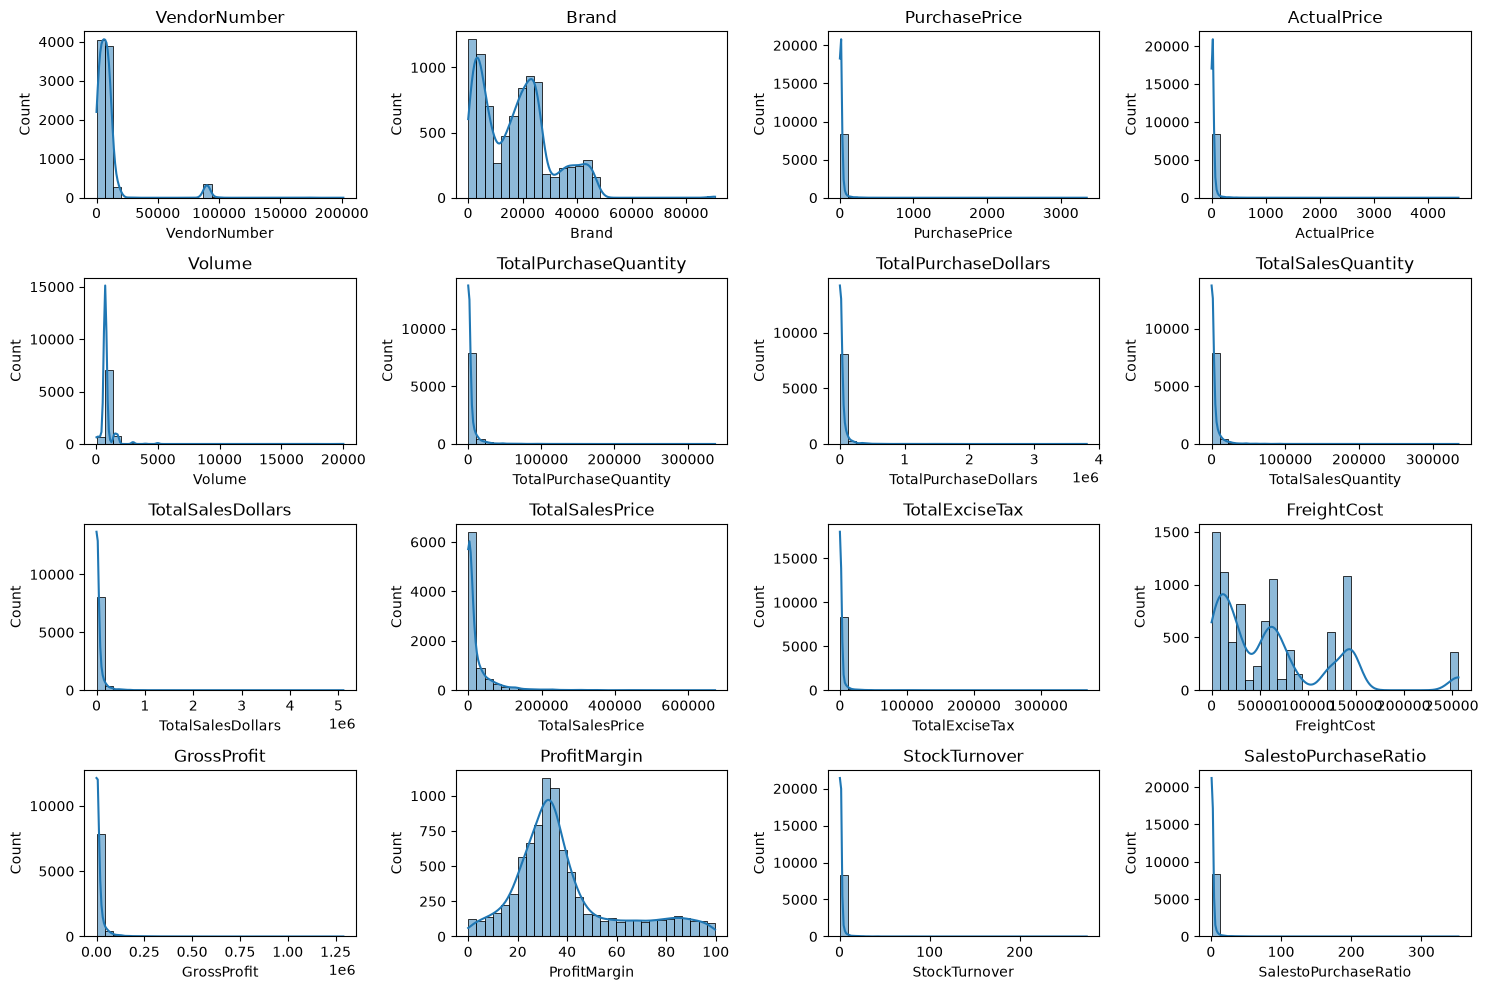

In [11]:
# Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)  # Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

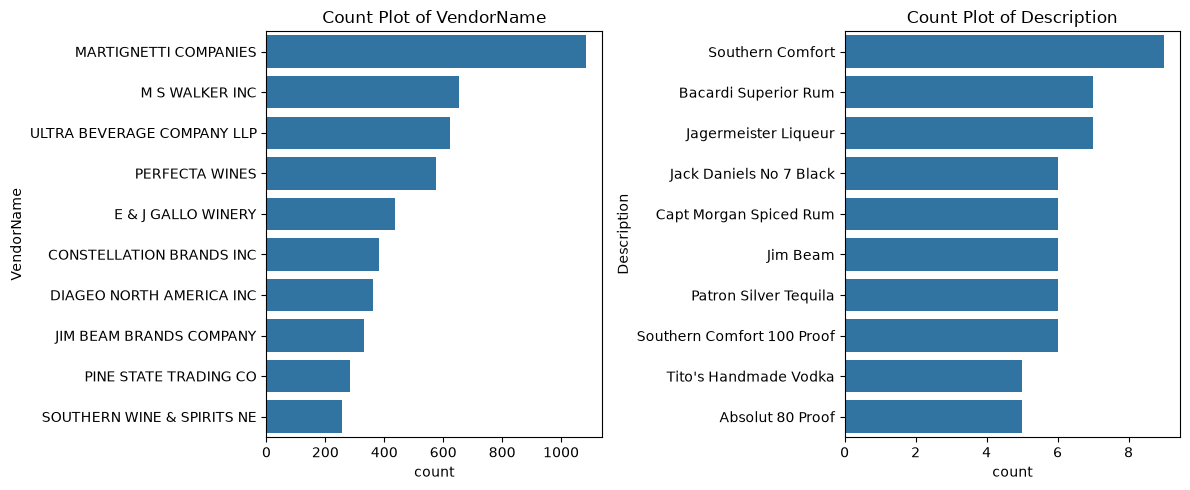

In [12]:
# Count Plots for Categorical Columns
categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))

for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)
    sns.countplot(y=df[col], order=df[col].value_counts().index[:10])  # Top 10 categories
    plt.title(f"Count Plot of {col}")

plt.tight_layout()
plt.show()

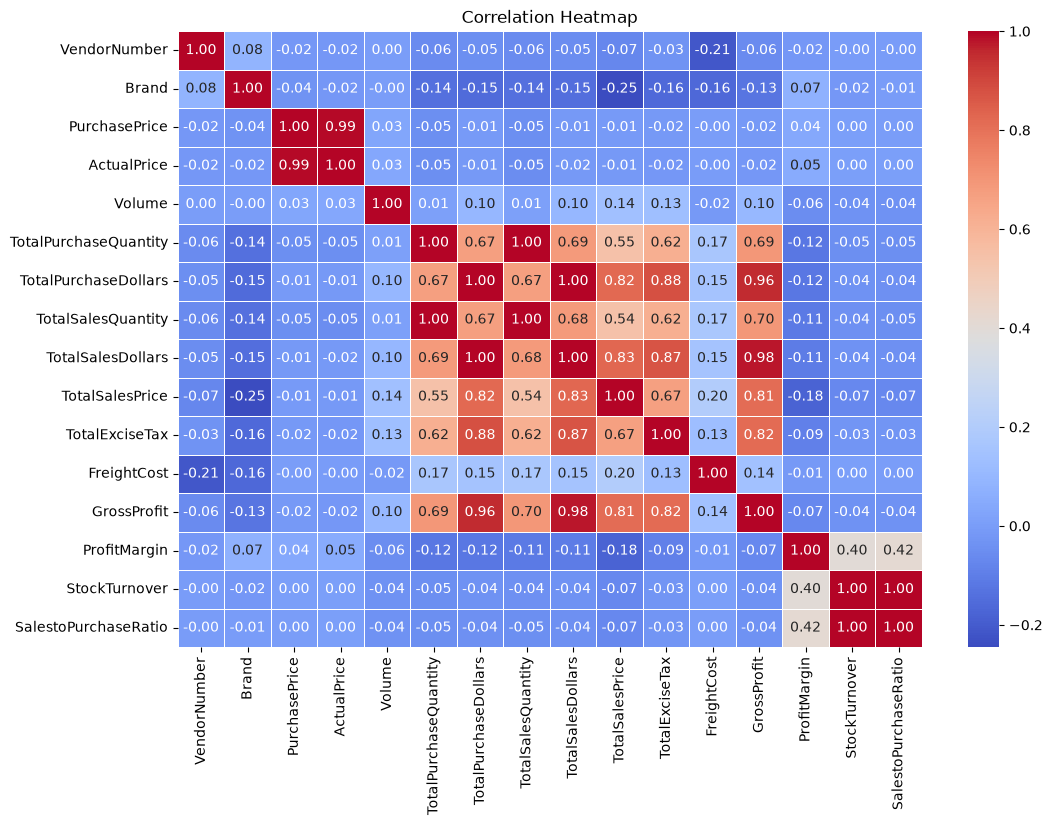

In [14]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))

correlation_matrix = df[numerical_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

## Correlation Insights

- **PurchasePrice** has weak correlations with **TotalSalesDollars (−0.012)** and **GrossProfit (−0.016)**, suggesting that price variations do not significantly impact sales revenue or profit.
- Strong correlation between total purchase quantity and total sales quantity (**0.999**), confirming efficient inventory turnover.
- Negative correlation between profit margin and total sales price (**−0.179**) suggests that as sales price increases, margins decrease, possibly due to competitive pricing pressures.
- **StockTurnover** has weak negative correlations with both **GrossProfit (−0.038)** and **ProfitMargin (−0.055)**, indicating that faster turnover does not necessarily result in higher profitability.

## Data Analysis

Identify brands that need promotional or pricing adjustments, which exhibit lower sales performance but higher profit margins.

In [18]:
brand_performance=df.groupby('Description').agg({
    'TotalSalesDollars': 'sum',
    'ProfitMargin': 'mean'
}).reset_index()

In [19]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)


In [20]:
print("Low sales threshold:", low_sales_threshold)
print("High margin threshold:", high_margin_threshold)

Low sales threshold: 560.299
High margin threshold: 64.97017552750113


In [21]:
# Filter brands with low sales but high profit margins
target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) &
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.99,66.466466
2369,Debauchery Pnt Nr,11.58,65.975820
2070,Concannon Glen Ellen Wh Zin,15.95,83.448276
2188,Crown Royal Apple,27.86,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.96,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.68,76.747312
2271,Dad's Hat Rye Whiskey,538.89,81.851584
57,A Bichot Clos Marechaudes,539.94,67.740860
6245,Sbragia Home Ranch Merlot,549.75,66.444748


In [23]:
brand_performance = brand_performance[
    brand_performance['TotalSalesDollars'] < 10000
]  # for better visualization

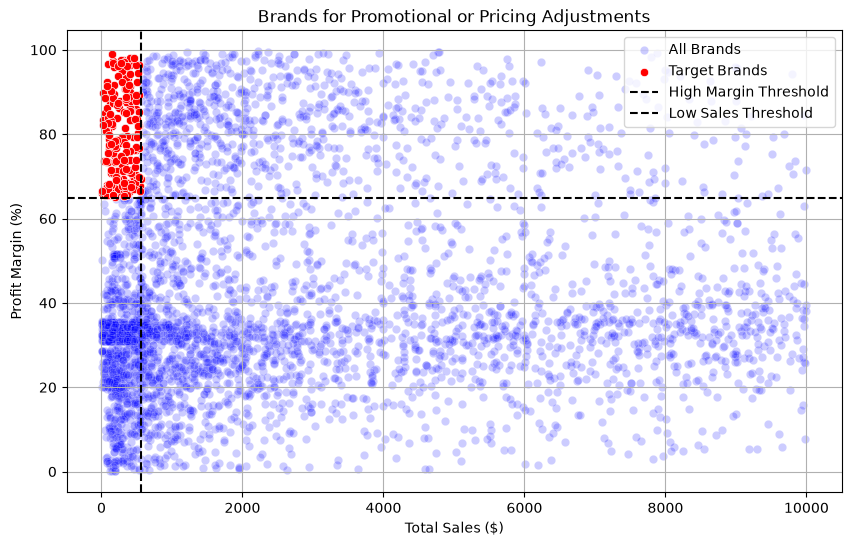

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=brand_performance,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='blue',
    label='All Brands',
    alpha=0.2
)

sns.scatterplot(
    data=target_brands,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='red',
    label='Target Brands'
)

plt.axhline(
    high_margin_threshold,
    linestyle='--',
    color='black',
    label='High Margin Threshold'
)

plt.axvline(
    low_sales_threshold,
    linestyle='--',
    color='black',
    label='Low Sales Threshold'
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

Which vendors and brands demonstrate the highest sales performance?

In [27]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return str(value)

In [28]:
# Top Vendors & Brands by Sales Performance
top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)
top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

top_vendors

VendorName
DIAGEO NORTH AMERICA INC      67990099.42
MARTIGNETTI COMPANIES         39330359.36
PERNOD RICARD USA             32063196.19
JIM BEAM BRANDS COMPANY       31423020.46
BACARDI USA INC               24854817.14
CONSTELLATION BRANDS INC      24218745.65
E & J GALLO WINERY            18399899.46
BROWN-FORMAN CORP             18247230.65
ULTRA BEVERAGE COMPANY LLP    16502544.31
M S WALKER INC                14706458.51
Name: TotalSalesDollars, dtype: float64

In [29]:
top_brands

Description
Jack Daniels No 7 Black    7964746.76
Tito's Handmade Vodka      7399657.58
Grey Goose Vodka           7209608.06
Capt Morgan Spiced Rum     6356320.62
Absolut 80 Proof           6244752.03
Jameson Irish Whiskey      5715759.69
Ketel One Vodka            5070083.56
Baileys Irish Cream        4150122.07
Kahlua                     3604858.66
Tanqueray                  3456697.90
Name: TotalSalesDollars, dtype: float64

In [30]:
top_brands.apply(lambda x: format_dollars(x))

Description
Jack Daniels No 7 Black    $7.96M
Tito's Handmade Vodka      $7.40M
Grey Goose Vodka           $7.21M
Capt Morgan Spiced Rum     $6.36M
Absolut 80 Proof           $6.24M
Jameson Irish Whiskey      $5.72M
Ketel One Vodka            $5.07M
Baileys Irish Cream        $4.15M
Kahlua                     $3.60M
Tanqueray                  $3.46M
Name: TotalSalesDollars, dtype: str

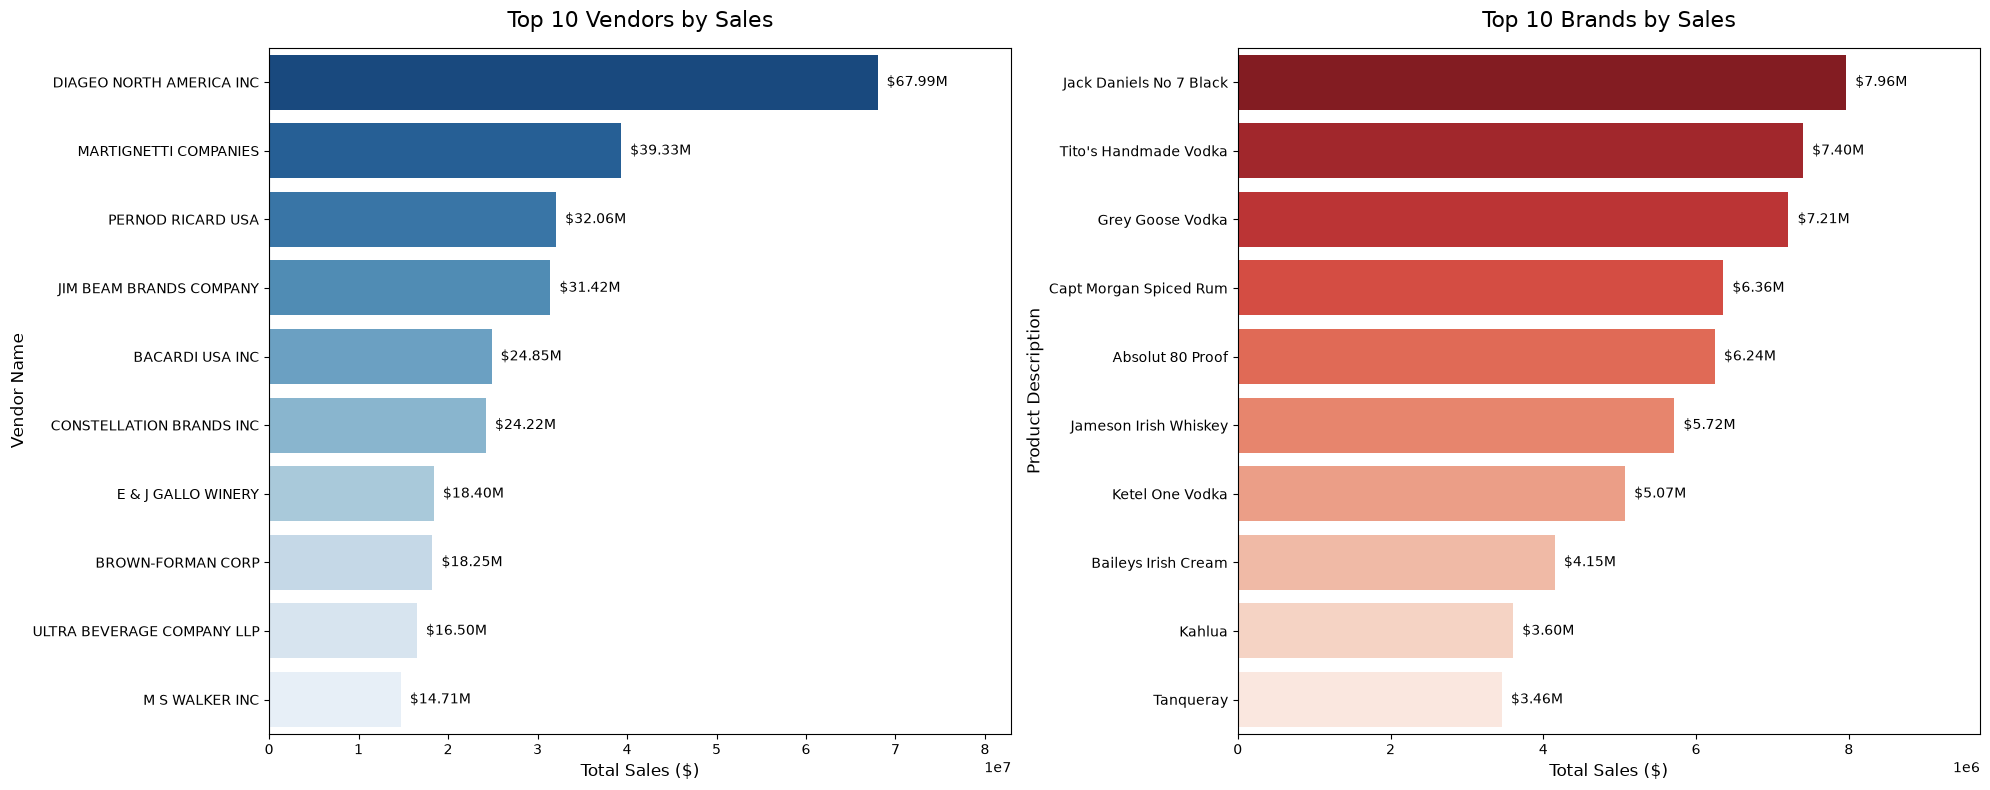

In [33]:
# Top Vendors and Brands by Sales — Improved Readability
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot for Top Vendors
ax1 = sns.barplot(
    y=top_vendors.index,
    x=top_vendors.values,
    hue=top_vendors.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)
ax1.set_title("Top 10 Vendors by Sales", fontsize=16, pad=15)
ax1.set_xlabel("Total Sales ($)", fontsize=12)
ax1.set_ylabel("Vendor Name", fontsize=12)
ax1.tick_params(axis="y", labelsize=10)
ax1.tick_params(axis="x", labelsize=10)

for bar in ax1.patches:
    width = bar.get_width()
    ax1.text(
        width + max(top_vendors.values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        format_dollars(width),
        ha="left",
        va="center",
        fontsize=10
    )

ax1.set_xlim(0, max(top_vendors.values) * 1.22)

# Plot for Top Brands
ax2 = sns.barplot(
    y=top_brands.index.astype(str),
    x=top_brands.values,
    hue=top_brands.index.astype(str),
    palette="Reds_r",
    legend=False,
    ax=axes[1]
)
ax2.set_title("Top 10 Brands by Sales", fontsize=16, pad=15)
ax2.set_xlabel("Total Sales ($)", fontsize=12)
ax2.set_ylabel("Product Description", fontsize=12)
ax2.tick_params(axis="y", labelsize=10)
ax2.tick_params(axis="x", labelsize=10)

for bar in ax2.patches:
    width = bar.get_width()
    ax2.text(
        width + max(top_brands.values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        format_dollars(width),
        ha="left",
        va="center",
        fontsize=10
    )

ax2.set_xlim(0, max(top_brands.values) * 1.22)

plt.tight_layout()
plt.show()

Which vendors contribute the most to total purchase dollars?

Vendor performance shape: (119, 4)


,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
0,DIAGEO NORTH AMERICA INC,$50.10M,$17.89M,$67.99M,16.30
1,MARTIGNETTI COMPANIES,$25.50M,$13.83M,$39.33M,8.30
2,PERNOD RICARD USA,$23.85M,$8.21M,$32.06M,7.76
3,JIM BEAM BRANDS COMPANY,$23.49M,$7.93M,$31.42M,7.64
4,BACARDI USA INC,$17.43M,$7.42M,$24.85M,5.67
5,CONSTELLATION BRANDS INC,$15.27M,$8.95M,$24.22M,4.97
6,BROWN-FORMAN CORP,$13.24M,$5.01M,$18.25M,4.31
7,E & J GALLO WINERY,$12.07M,$6.33M,$18.40M,3.93
8,ULTRA BEVERAGE COMPANY LLP,$11.17M,$5.34M,$16.50M,3.63
9,M S WALKER INC,$9.76M,$4.94M,$14.71M,3.18


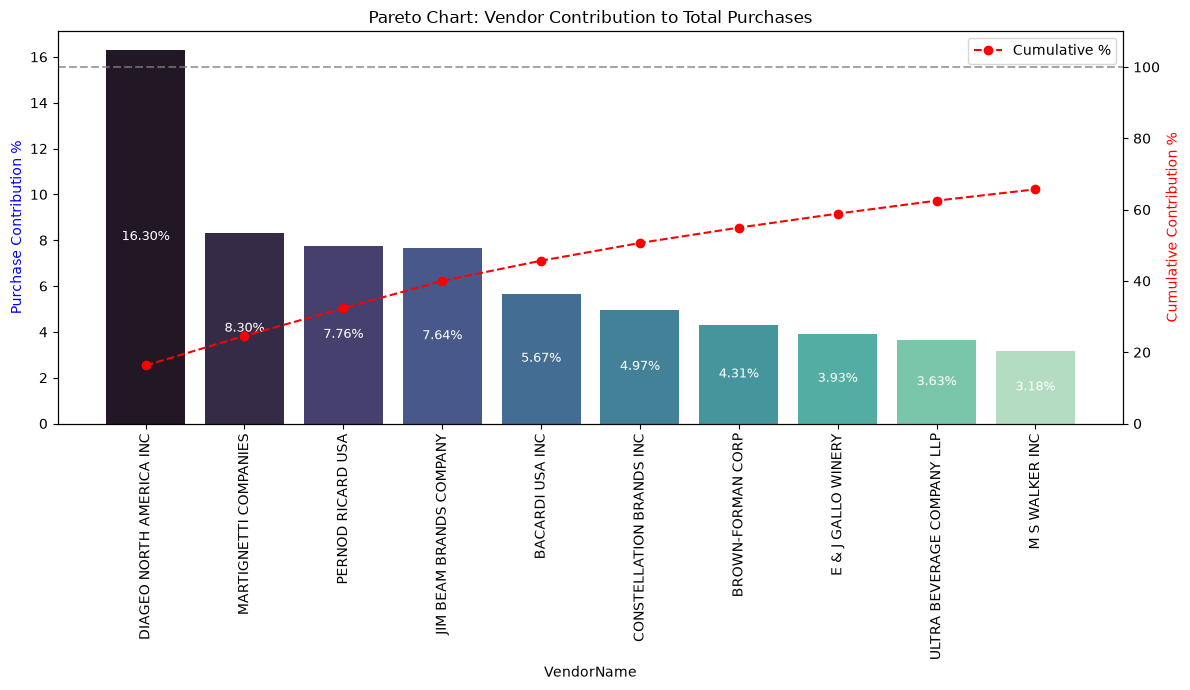

In [68]:

# 1. Aggregate financial metrics by vendor
vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars': 'sum',
    'GrossProfit': 'sum',
    'TotalSalesDollars': 'sum'
}).reset_index()

print("Vendor performance shape:", vendor_performance.shape)

# 2. Calculate purchase contribution percentage
vendor_performance['PurchaseContribution%'] = (
    vendor_performance['TotalPurchaseDollars']
    / vendor_performance['TotalPurchaseDollars'].sum()
) * 100

# 3. Sort vendors from highest to lowest contribution
vendor_performance = vendor_performance.sort_values(
    'PurchaseContribution%',
    ascending=False
).reset_index(drop=True)

# 4. Select the top 10 vendors
top_vendors = vendor_performance.head(10).copy()

# Optional: display formatted financial values without changing calculations
top_vendors_display = top_vendors.copy()

for col in ['TotalSalesDollars', 'TotalPurchaseDollars', 'GrossProfit']:
    top_vendors_display[col] = top_vendors_display[col].apply(format_dollars)

display(top_vendors_display.round(2))

# 5. Calculate cumulative contribution
top_vendors['Cumulative_Contribution%'] = (
    top_vendors['PurchaseContribution%'].cumsum()
)

# 6. Create the Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=top_vendors,
    x='VendorName',
    y='PurchaseContribution%',
    palette='mako',
    ax=ax1
)

# Percentage labels inside the bars
for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(
        i,
        value / 2,
        f'{value:.2f}%',
        ha='center',
        va='center',
        fontsize=9,
        color='white'
    )

# Cumulative contribution line on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    range(len(top_vendors)),
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative %',
    zorder=5
)

# Chart formatting
ax1.set_xticks(range(len(top_vendors)))
ax1.set_xticklabels(
    top_vendors['VendorName'],
    rotation=90,
    ha='center'
)

ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.axhline(
    y=100,
    color='gray',
    linestyle='dashed',
    alpha=0.7
)

ax2.legend(loc='upper right')
ax2.set_ylim(
    0,
    max(110, top_vendors['Cumulative_Contribution%'].max() + 10)
)

plt.tight_layout()
plt.show()


How much of total procurement is dependent on the top vendors?

In [69]:
print(
    f"Total Purchase Contribution of top 10 vendors is "
    f"{round(top_vendors['PurchaseContribution%'].sum(), 2)}%"
)

Total Purchase Contribution of top 10 vendors is 65.69%


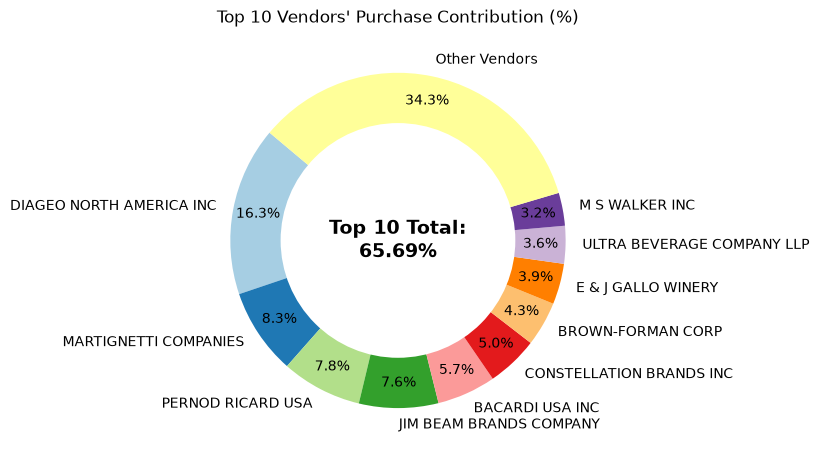

In [70]:

# Prepare data for the donut chart
vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(
    top_vendors['PurchaseContribution%'].values
)

total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# Draw a white circle in the center to create a donut effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add total contribution annotation in the center
plt.text(
    0, 0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendors' Purchase Contribution (%)")
plt.tight_layout()
plt.show()


Does purchasing in bulk reduce the unit price, and what is the optimal purchase volume for cost savings?